In [ ]:
%pip install streamlit

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.model_selection import RandomizedSearchCV


In [ ]:
#loading the dataset
df=pd.read_csv('/content/Food delivery.csv')
df

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45588,0x7c09,JAPRES04DEL01,30,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35:00,11:45:00,conditions Windy,High,1,Meal,motorcycle,0,No,Metropolitian,(min) 32
45589,0xd641,AGRRES16DEL01,21,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55:00,20:10:00,conditions Windy,Jam,0,Buffet,motorcycle,1,No,Metropolitian,(min) 36
45590,0x4f8d,CHENRES08DEL03,30,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50:00,00:05:00,conditions Cloudy,Low,1,Drinks,scooter,0,No,Metropolitian,(min) 16
45591,0x5eee,COIMBRES11DEL01,20,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35:00,13:40:00,conditions Cloudy,High,0,Snack,motorcycle,1,No,Metropolitian,(min) 26


In [ ]:
df.shape

(45593, 20)

In [ ]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [ ]:
df.tail()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
45588,0x7c09,JAPRES04DEL01,30,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35:00,11:45:00,conditions Windy,High,1,Meal,motorcycle,0,No,Metropolitian,(min) 32
45589,0xd641,AGRRES16DEL01,21,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55:00,20:10:00,conditions Windy,Jam,0,Buffet,motorcycle,1,No,Metropolitian,(min) 36
45590,0x4f8d,CHENRES08DEL03,30,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50:00,00:05:00,conditions Cloudy,Low,1,Drinks,scooter,0,No,Metropolitian,(min) 16
45591,0x5eee,COIMBRES11DEL01,20,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35:00,13:40:00,conditions Cloudy,High,0,Snack,motorcycle,1,No,Metropolitian,(min) 26
45592,0x5fb2,RANCHIRES09DEL02,23,4.9,23.351058,85.325731,23.431058,85.405731,02-03-2022,17:10:00,17:15:00,conditions Fog,Medium,2,Snack,scooter,1,No,Metropolitian,(min) 36


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [ ]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [ ]:
df.isna().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,0
Delivery_person_Ratings,0
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
for col in df.columns:
    print(df[col].value_counts(dropna=False))
    print("\n")
    #age, Delivery_person_Ratings, Time_Orderd, Weatherconditions, Road_traffic_density,
    #multiple_deliveries, Festival, City --- contains Nan values which is missing values

ID
0x5fb2     1
0x4607     1
0xb379     1
0x5d6d     1
0x7a6a     1
          ..
0xdb64     1
0xc8b6     1
0x2784     1
0xd987     1
0xcdcd     1
Name: count, Length: 45593, dtype: int64


Delivery_person_ID
PUNERES01DEL01       67
JAPRES11DEL02        67
VADRES08DEL02        66
RANCHIRES02DEL01     66
HYDRES04DEL02        66
                     ..
BHPRES15DEL03         7
GOARES01DEL03         7
KOLRES09DEL03         6
KOCRES16DEL03         6
BHPRES010DEL03        5
Name: count, Length: 1320, dtype: int64


Delivery_person_Age
35      2262
36      2260
37      2227
30      2226
38      2219
24      2210
32      2202
22      2196
29      2191
33      2187
28      2179
25      2174
34      2166
26      2159
21      2153
27      2150
39      2144
20      2136
31      2120
23      2087
NaN     1854
50        53
15        38
Name: count, dtype: int64


Delivery_person_Ratings
4.8     7148
4.7     7142
4.9     7041
4.6     6940
5       3996
4.5     3303
NaN     1908
4.1     1430
4.2     141

In [ ]:
#removing conditions value in weather
df['Weatherconditions']=df['Weatherconditions'].apply(lambda x: x.split(' ')[1] if pd.notnull(x) else x)

In [ ]:
df['Weatherconditions']

,Weatherconditions
0,Sunny
1,Stormy
2,Sandstorms
3,Sunny
4,Cloudy
...,...
45588,Windy
45589,Windy
45590,Cloudy
45591,Cloudy


In [ ]:
  #removing (min)from time taken
df['Time_taken(min)']=df['Time_taken(min)'].apply(lambda x : int(x.split(' ')[1] if pd.notnull(x) else x))

In [ ]:
df['Time_taken(min)']

,Time_taken(min)
0,24
1,33
2,26
3,21
4,30
...,...
45588,32
45589,36
45590,16
45591,26


In [ ]:
#replacing Nan values with np.nan
for i in df.select_dtypes(include=object).columns:
  df[i]=df[i].str.strip()
  df[i]=df[i].replace('NaN',np.nan)

In [ ]:
#filling missing values
df.isna().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


In [ ]:
#filling missing values
obj_col=['Delivery_person_Age','Delivery_person_Ratings','Time_Orderd','Weatherconditions','Road_traffic_density','multiple_deliveries','Festival','City']

for i in obj_col:
  df[i]=df[i].fillna(df[i].mode()[0])


In [ ]:
df.isna().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


In [ ]:
#converting object to numeric values

df['Delivery_person_Age']=df['Delivery_person_Age'].astype(int)
df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].astype(float)
df['multiple_deliveries']=df['multiple_deliveries'].astype(int)

In [ ]:
# converting ratings 6 to 5 or below 5

df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].clip(upper=5)

In [ ]:
#converting to date format
hour = pd.to_datetime(df['Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour

In [ ]:
#EDA
df['Time_taken(min)'].describe()


,Time_taken(min)
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


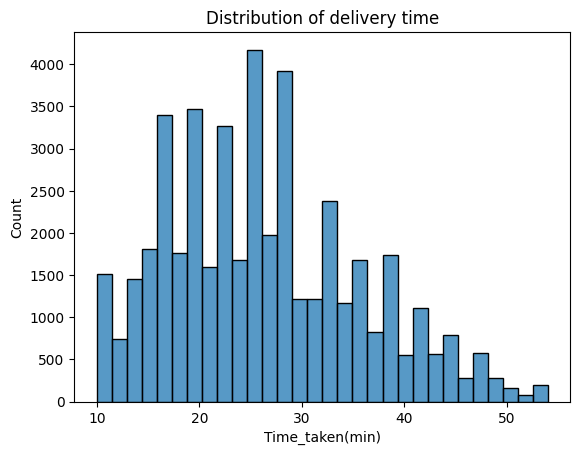

In [ ]:
sns.histplot(df['Time_taken(min)'],bins=30)
plt.title('Distribution of delivery time')
plt.show()

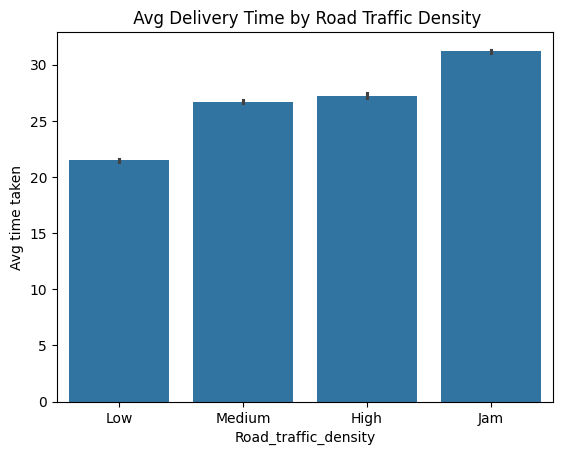

In [ ]:
sns.barplot(x='Road_traffic_density',y='Time_taken(min)',data=df,estimator='mean',order=["Low", "Medium", "High", "Jam"])
plt.title(" Avg Delivery Time by Road Traffic Density")
plt.ylabel('Avg time taken')

plt.show()


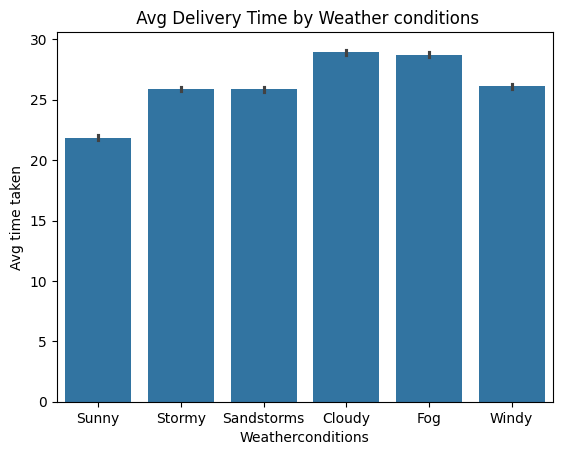

In [ ]:
sns.barplot(x='Weatherconditions',y='Time_taken(min)',data=df,estimator='mean')
plt.title(" Avg Delivery Time by Weather conditions")
plt.ylabel('Avg time taken')
plt.show()


Text(0, 0.5, 'Avg time taken')

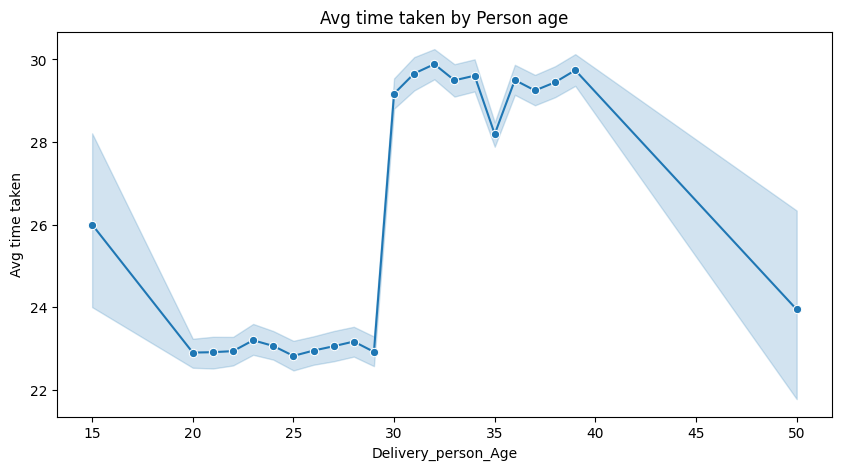

In [ ]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Delivery_person_Age',y='Time_taken(min)',data=df,estimator='mean',marker='o')
plt.title('Avg time taken by Person age')
plt.ylabel('Avg time taken')

In [ ]:
#average delivery time during festivals
df.groupby('Festival') ['Time_taken(min)'].mean()

,Time_taken(min)
Festival,
No,25.909256
Yes,45.517857


In [ ]:
#average delivery time during festivals
df.groupby('Festival') ['Time_taken(min)'].mean()

,Time_taken(min)
Festival,
No,25.909256
Yes,45.517857


In [ ]:
#average delivery time in city
df.groupby('City') ['Time_taken(min)'].mean()

,Time_taken(min)
City,
Metropolitian,27.136486
Semi-Urban,49.731707
Urban,22.984017


In [ ]:
df.dtypes

,0
ID,object
Delivery_person_ID,object
Delivery_person_Age,int64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object


<Axes: >

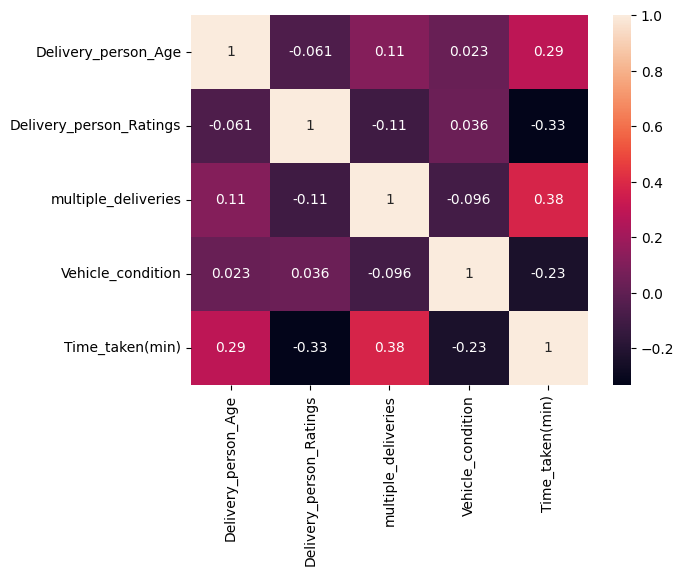

In [ ]:
cols=['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries','Vehicle_condition','Time_taken(min)']
sns.heatmap(df[cols].corr(),annot=True)


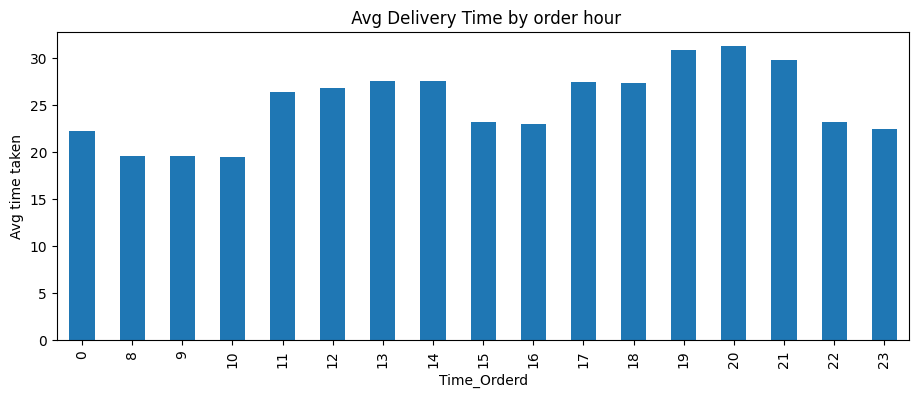

In [ ]:
plt.figure(figsize=(11,4))
df.groupby(hour) ['Time_taken(min)'].mean().plot(kind='bar')
plt.title(" Avg Delivery Time by order hour")
plt.ylabel('Avg time taken')
plt.show()


In [ ]:
#feature engineering


In [ ]:
def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of

    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """
    r = 3956 if miles else 6371
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * r


In [ ]:
#adding new col distance km
df['distance_km']=calculate_series_distance(df['Restaurant_latitude'],df['Restaurant_longitude'],df['Delivery_location_latitude'],df['Delivery_location_longitude'])

In [ ]:
df['distance_km'].describe()

,distance_km
count,45593.000000
mean,99.303911
std,1099.731281
min,1.465067
25%,4.663493
50%,9.264281
75%,13.763977
max,19692.674606


In [ ]:
df[df['distance_km']>100]

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
92,0xc042,AGRRES010DEL01,34,4.7,-27.163303,78.057044,27.233303,78.127044,16-02-2022,23:00:00,...,Sandstorms,Low,1,Drinks,scooter,0,No,Metropolitian,15,6048.631240
283,0xc044,AGRRES12DEL03,32,4.7,-27.165108,78.015053,27.225108,78.075053,13-02-2022,20:55:00,...,Sandstorms,Jam,2,Meal,scooter,1,No,Metropolitian,31,6047.919478
289,0x4db,PUNERES02DEL03,35,4.8,-18.551440,-73.804855,18.611440,73.864855,05-03-2022,21:55:00,...,Stormy,Jam,2,Meal,scooter,0,No,Urban,12,16612.239055
425,0xc003,DEHRES13DEL02,35,4.8,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,21:55:00,...,Fog,Low,3,Snack,scooter,1,No,Metropolitian,20,17744.205087
534,0x473,MYSRES07DEL03,35,4.8,-12.325461,-76.632278,12.385461,76.692278,03-03-2022,21:55:00,...,Fog,Low,3,Buffet,scooter,1,No,Metropolitian,16,17118.828366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44933,0xc0c2,AURGRES03DEL03,30,4.9,-19.874733,75.353942,19.904733,75.383942,15-02-2022,22:20:00,...,Fog,Low,1,Buffet,motorcycle,0,No,Metropolitian,15,4423.276011
45020,0x56b,PUNERES04DEL01,35,4.8,-18.514210,73.838429,18.524210,73.848429,21-03-2022,21:55:00,...,Fog,Low,3,Drinks,electric_scooter,1,No,Metropolitian,30,4118.484540
45108,0xc01b,GOARES18DEL01,35,4.8,-15.493950,-73.827423,15.563950,73.897423,16-02-2022,21:55:00,...,Windy,Jam,2,Meal,scooter,1,No,Urban,19,16560.629487
45182,0xc0c7,KNPRES16DEL02,30,4.0,-26.482581,80.315628,26.532581,80.365628,17-02-2022,22:25:00,...,Sandstorms,Low,0,Drinks,motorcycle,1,No,Metropolitian,34,5895.019482


In [ ]:
#dropping distance km which is greater than 100(431 rows)
df=df[df['distance_km']<100].reset_index(drop=True)
df

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,Sunny,High,2,Snack,motorcycle,0,No,Urban,24,3.025149
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33,20.183530
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26,1.552758
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,...,Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21,7.790401
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,...,Cloudy,High,1,Snack,scooter,1,No,Metropolitian,30,6.210138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45157,0x7c09,JAPRES04DEL01,30,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35:00,...,Windy,High,1,Meal,motorcycle,0,No,Metropolitian,32,1.489846
45158,0xd641,AGRRES16DEL01,21,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55:00,...,Windy,Jam,0,Buffet,motorcycle,1,No,Metropolitian,36,11.007735
45159,0x4f8d,CHENRES08DEL03,30,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50:00,...,Cloudy,Low,1,Drinks,scooter,0,No,Metropolitian,16,4.657195
45160,0x5eee,COIMBRES11DEL01,20,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35:00,...,Cloudy,High,0,Snack,motorcycle,1,No,Metropolitian,26,6.232393


In [ ]:

df['order_hour']=pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S', errors='coerce').dt.hour
df

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km,order_hour
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,High,2,Snack,motorcycle,0,No,Urban,24,3.025149,11
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,Jam,2,Snack,scooter,1,No,Metropolitian,33,20.183530,19
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,Low,0,Drinks,motorcycle,1,No,Urban,26,1.552758,8
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,...,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21,7.790401,18
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,...,High,1,Snack,scooter,1,No,Metropolitian,30,6.210138,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45157,0x7c09,JAPRES04DEL01,30,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35:00,...,High,1,Meal,motorcycle,0,No,Metropolitian,32,1.489846,11
45158,0xd641,AGRRES16DEL01,21,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55:00,...,Jam,0,Buffet,motorcycle,1,No,Metropolitian,36,11.007735,19
45159,0x4f8d,CHENRES08DEL03,30,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50:00,...,Low,1,Drinks,scooter,0,No,Metropolitian,16,4.657195,23
45160,0x5eee,COIMBRES11DEL01,20,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35:00,...,High,0,Snack,motorcycle,1,No,Metropolitian,26,6.232393,13


In [ ]:
df['order_hour'].value_counts()

,count
order_hour,
21,6127
19,4578
22,4559
20,4524
23,4490
18,4464
17,4267
10,1987
11,1954


In [ ]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)',
       'distance_km', 'order_hour'],
      dtype='object')

In [ ]:
features=['Delivery_person_Age','Delivery_person_Ratings','distance_km','order_hour','Weatherconditions','Road_traffic_density',
          'Vehicle_condition','Type_of_order','Type_of_vehicle','multiple_deliveries','Festival','City']

In [ ]:
#spliting to X and y

X=df[features]
y=df['Time_taken(min)']

In [ ]:
X.dtypes

,0
Delivery_person_Age,int64
Delivery_person_Ratings,float64
distance_km,float64
order_hour,int32
Weatherconditions,object
Road_traffic_density,object
Vehicle_condition,int64
Type_of_order,object
Type_of_vehicle,object
multiple_deliveries,int64


In [ ]:
#ordinal encoding using mapping
traffic_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2,
    'Jam': 3
}

X['Road_traffic_density'] = X['Road_traffic_density'].map(traffic_mapping)

/tmp/ipykernel_2426/2543222334.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Road_traffic_density'] = X['Road_traffic_density'].map(traffic_mapping)


In [ ]:
#nominal encoding using get dummies
X=pd.get_dummies(X,columns=['Type_of_order','Type_of_vehicle','Festival','City','Weatherconditions'],drop_first=True,dtype=int)

In [ ]:
#train test split of X and y

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=1)

In [ ]:
#scaling

scalar=StandardScaler()
X_train=scalar.fit_transform(X_train)
X_test=scalar.transform(X_test)

In [ ]:
X_train
X_test

array([[ 1.59925629, -1.3575454 ,  1.98292564, ...,  2.23551112,
        -0.43514801, -0.44196718],
       [-1.34071138,  1.11548869,  1.80823522, ..., -0.447325  ,
        -0.43514801, -0.44196718],
       [ 0.21574209,  0.49723017, -0.05406787, ..., -0.447325  ,
         2.29806867, -0.44196718],
       ...,
       [-0.13013646,  0.49723017, -0.90315885, ...,  2.23551112,
        -0.43514801, -0.44196718],
       [ 0.73455992, -0.12102835, -0.69156937, ..., -0.447325  ,
        -0.43514801, -0.44196718],
       [ 1.59925629, -1.3575454 , -1.458874  , ..., -0.447325  ,
        -0.43514801,  2.26261145]])

In [ ]:
#model creation

#linear regression
#knn
#decision teee
#random forest
#XG boost

lr=LinearRegression()
knn=KNeighborsRegressor()
tree=DecisionTreeRegressor()
forest=RandomForestRegressor()
xgb=XGBRegressor()

models=[lr,knn,tree,forest,xgb]

for model in models:
  print(model)
  print('-'*100)
  model.fit(X_train,y_train)
  y_test_pred=model.predict(X_test)
  y_train_pred=model.predict(X_train)

  mae=mean_absolute_error(y_test,y_test_pred)
  rmse=mean_squared_error(y_test,y_test_pred)
  r2_score_test=r2_score(y_test,y_test_pred)
  r2_score_train=r2_score(y_train,y_train_pred)
  print('mae:',mae)
  print('rmse :',rmse)
  print('r2 score of training data:',r2_score_train)
  print('r2 score of test data:',r2_score_test)
  print('*' *100)
  print()

LinearRegression()
----------------------------------------------------------------------------------------------------
mae: 4.893659972451012
rmse : 37.40907735172019
r2 score of training data: 0.5824754187290291
r2 score of test data: 0.5759785685008474
****************************************************************************************************

KNeighborsRegressor()
----------------------------------------------------------------------------------------------------
mae: 4.062437728329459
rmse : 27.737752684600913
r2 score of training data: 0.8007055850544725
r2 score of test data: 0.6856003293181163
****************************************************************************************************

DecisionTreeRegressor()
----------------------------------------------------------------------------------------------------
mae: 4.198715819771947
rmse : 30.593490534706078
r2 score of training data: 1.0
r2 score of test data: 0.6532313393052626
*********************************

In [ ]:
#validation


#RANDOM FOREST
rf_params = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search_rf = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_params,
    n_iter=25,        # Number of random combinations to try
    cv= 3,
    scoring='r2',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search_rf.fit(X_train, y_train)

print("--- Random Forest Best Results ---")
print("Best Parameters:", random_search_rf.best_params_)
print(f"Best CV R2 Score: {random_search_rf.best_score_:.4f}")
best_rf = random_search_rf.best_estimator_
print(f"Test R2 Score: {r2_score(y_test, best_rf.predict(X_test)):.4f}\n")




Fitting 3 folds for each of 25 candidates, totalling 75 fits
--- Random Forest Best Results ---
Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 20}
Best CV R2 Score: 0.8183
Test R2 Score: 0.8212



In [ ]:
xgb_param_dist={
    'n_estimators':[300,500,800],
    'max_depth':[3,4,5,6,8],
    'learning_rate':[0.01,0.03,0.05,0.1],
    'subsample':[0.7,0.8,0.9,1.0],
    'colsample_bytree':[0.7,0.8,0.9,1.0],
    'reg_alpha':[0,0.1,0.5,1],
    'reg_lambda':[1,1.5,2]
}
xgb_search=RandomizedSearchCV(XGBRegressor(random_state=42),xgb_param_dist,n_iter=40,cv=3,
                              scoring='r2',random_state=42,n_jobs=-1)
xgb_search.fit(X_train,y_train)
print('best parameters are:',xgb_search.best_params_ )
print('best score is :',xgb_search.best_score_ )
xgb_best=xgb_search.best_estimator_



best parameters are: {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
best score is : 0.8231255610783895


In [ ]:
# 1. Grab a single sample from your test set (e.g., the first row of X_test)
sample_input = X_test[0:1]

# 2. Predict the delivery time using your trained XGBoost model
predicted_time = xgb_best.predict(sample_input)

# 3. Get the actual delivery time from y_test for comparison
actual_time = y_test[0:1]

print(f"Predicted Delivery Time: {predicted_time[0]:.2f} minutes")
print(f"Actual Delivery Time: {actual_time} minutes")

Predicted Delivery Time: 37.42 minutes
Actual Delivery Time: 9176    34
Name: Time_taken(min), dtype: int64 minutes


In [ ]:


# Save XGBoost model in JSON format
xgb_best.save_model("xgb_model.json")

# Save the fitted scaler
joblib.dump(scalar, "standardscalar.joblib")

print("XGBoost model and scaler saved successfully!")


XGBoost model and scaler saved successfully!
